In [245]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import seaborn as sns
from sklearn.metrics import classification_report

## Decision Tree

## importent info 


BMI = weight (kg)/height(m) to the power of 2


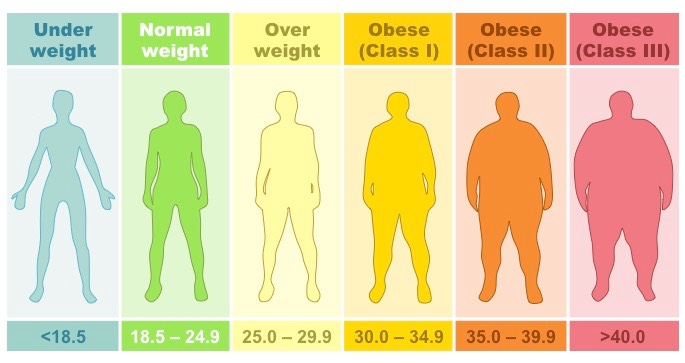


this pic comes from https://wecapable.com/body-mass-index-bmi-importance/


FAVC = Do you eat high caloric food frequently?


FCVC = Do you usually eat vegetables in your meals?


NCP = How many main meals do you have daily?


CAEC = Do you eat any food between meals?


SMOKE = Do you smoke?


CH2O = How much water do you drink daily?


SCC = Do you monitor the calories you eat daily?


FAF = How often do you have physical activity?


TUE = How much time do you use technological devices such as cell phone, videogames, television, computer and others?


CALC = How often do you drink alcohol? 


MTRANS = Which transportation do you usually use?


NObeyesdad = Obesity level

## Import Data

In [246]:



path = "data/ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(path)

## Binary Incodeing 

In [247]:
label_encoders = {}
for col in df.select_dtypes(include=["object"]).columns:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  label_encoders[col] = le

/tmp/ipykernel_941779/1821733809.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object"]).columns:


## Separate features and target

In [248]:
X = df.drop(columns=["NObeyesdad"])
y = df["NObeyesdad"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train

## Graphing The Tree

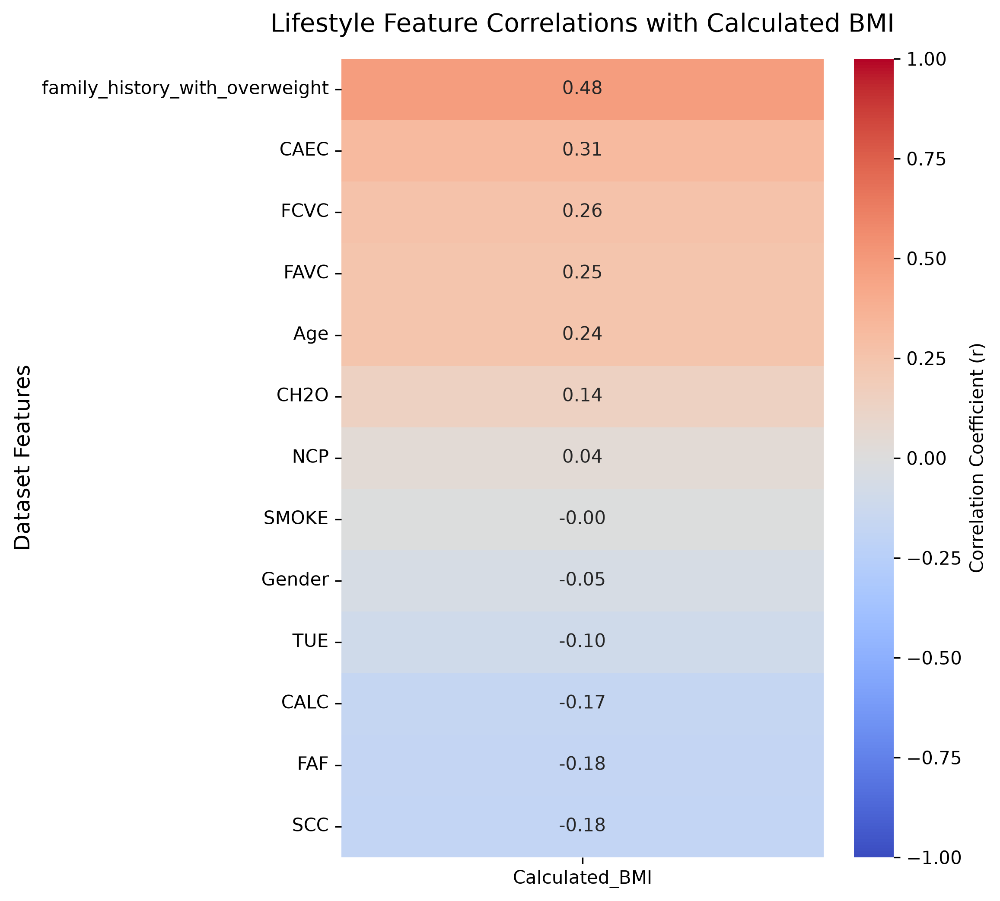

In [249]:
correct_order = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III",
]



# 1. Calculate BMI strictly for analysis
df['Calculated_BMI'] = df['Weight'] / (df['Height'] ** 2)

# 2. Select ONLY numeric columns, but explicitly drop columns that shouldn't be correlated here:
# - 'NObeyesdad' (target variable, which is a circular proxy for BMI)
# - 'MTRANS' (nominal categorical data where numbers have no linear scale)
# - Raw 'Weight' and 'Height' (optional: since BMI is calculated directly from them, 
cols_to_exclude = ['NObeyesdad', 'MTRANS', 'Weight', 'Height', 'Calculated_BMI']

# Get all numeric columns except the ones we want to exclude
numeric_features = df.select_dtypes(include=['number']).drop(columns=cols_to_exclude, errors='ignore')

# Add Calculated_BMI back temporarily so we can compute its correlations
numeric_features['Calculated_BMI'] = df['Calculated_BMI']

# 3. Compute correlation matrix and extract ONLY the BMI column
corr_matrix = numeric_features.corr()
bmi_corr = corr_matrix[['Calculated_BMI']].sort_values(by='Calculated_BMI', ascending=False)

# Drop 'Calculated_BMI' from itself so it doesn't show a redundant 1.0 correlation row
bmi_corr = bmi_corr.drop('Calculated_BMI', errors='ignore')

# 4. Plot as a clean, single-column vertical heatmap
plt.figure(figsize=(6, 8), dpi=300)
sns.heatmap(
    bmi_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, 
    vmax=1,
    cbar_kws={'label': 'Correlation Coefficient (r)'}
)

plt.title("Lifestyle Feature Correlations with Calculated BMI", fontsize=14, pad=15)
plt.ylabel("Dataset Features", fontsize=12)

plt.show()









## Tree


================ All Features (Depth = 3) ================
Test Accuracy: 63.36%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.829     0.607     0.701        56
      Normal_Weight      0.500     0.371     0.426        62
 Overweight_Level_I      0.789     0.192     0.309        78
Overweight_Level_II      0.815     0.914     0.862        58
     Obesity_Type_I      1.000     1.000     1.000        63
    Obesity_Type_II      0.493     0.661     0.565        56
   Obesity_Type_III      0.377     0.860     0.524        50

           accuracy                          0.634       423
          macro avg      0.686     0.658     0.627       423
       weighted avg      0.699     0.634     0.616       423

Saved tree plot to: pictures/tree_all_features_depth_3.svg


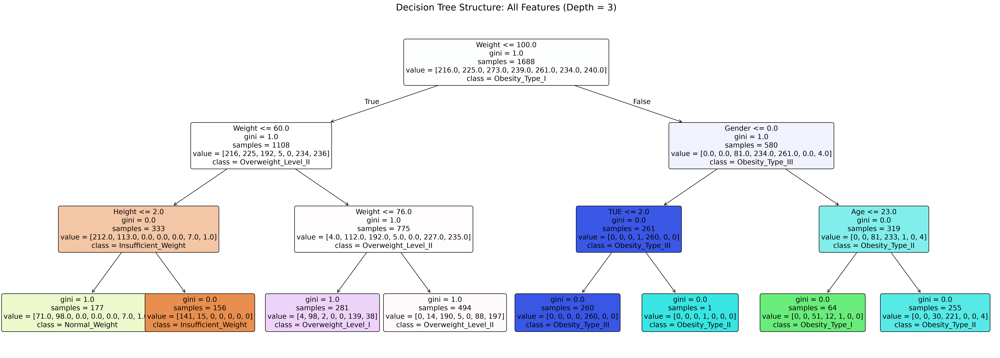

Saved confusion matrix to: pictures/confusion_matrix_all_features_depth_3.png



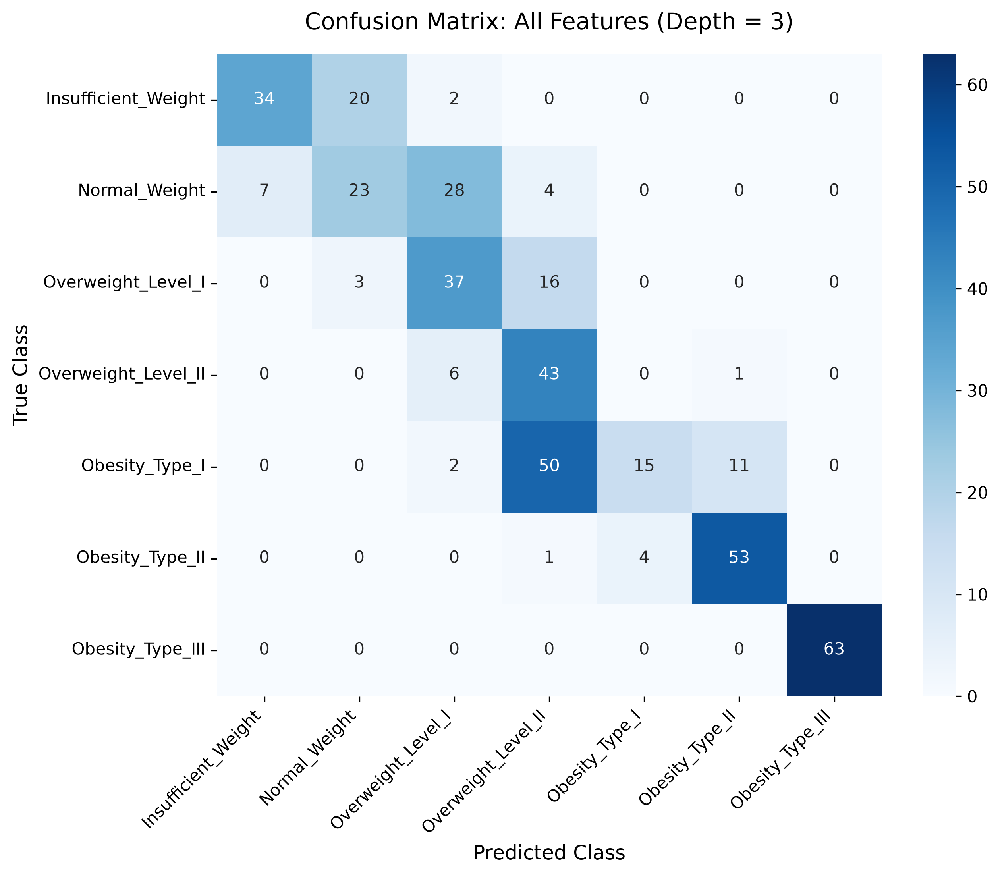


================ Lifestyle Only (Depth = 3) ================
Test Accuracy: 49.17%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.404     0.339     0.369        56
      Normal_Weight      0.407     0.355     0.379        62
 Overweight_Level_I      0.343     0.769     0.474        78
Overweight_Level_II      0.590     0.793     0.676        58
     Obesity_Type_I      0.884     0.968     0.924        63
    Obesity_Type_II      0.000     0.000     0.000        56
   Obesity_Type_III      0.000     0.000     0.000        50

           accuracy                          0.492       423
          macro avg      0.375     0.461     0.403       423
       weighted avg      0.389     0.492     0.422       423



/home/jordan/.local/share/mise/installs/python/3.14.7/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jordan/.local/share/mise/installs/python/3.14.7/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jordan/.local/share/mise/installs/python/3.14.7/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

Saved tree plot to: pictures/tree_lifestyle_only_depth_3.svg


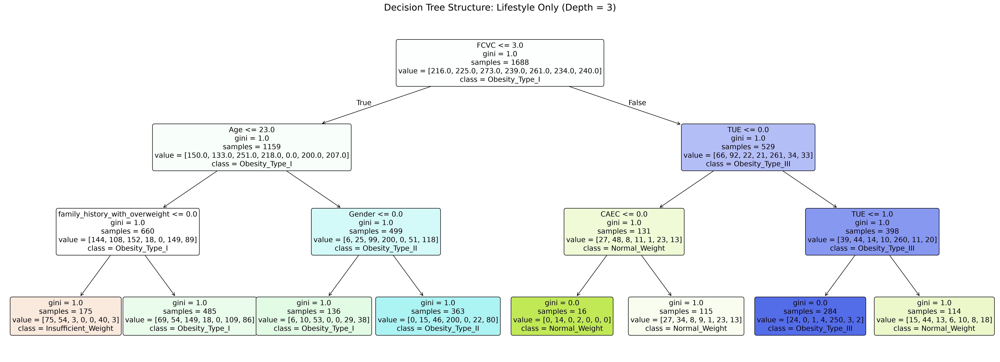

Saved confusion matrix to: pictures/confusion_matrix_lifestyle_only_depth_3.png



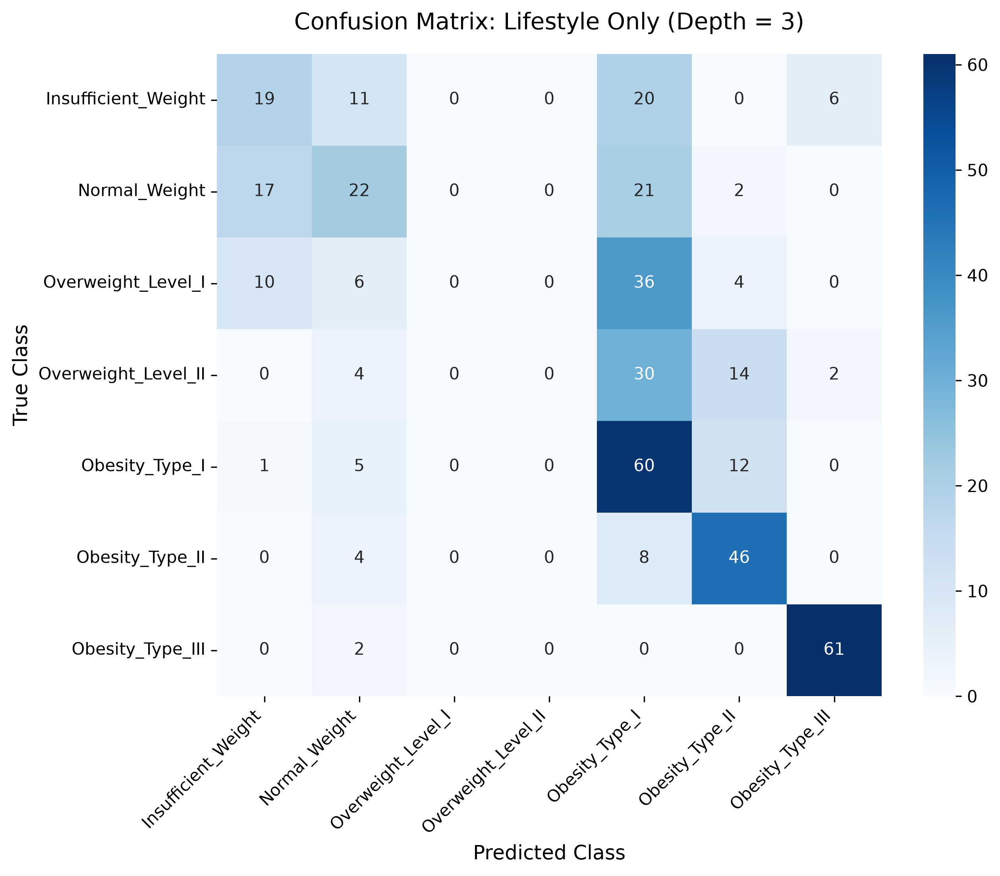


================ All Features (Depth = 6) ================
Test Accuracy: 90.31%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.900     0.964     0.931        56
      Normal_Weight      0.820     0.806     0.813        62
 Overweight_Level_I      0.947     0.923     0.935        78
Overweight_Level_II      0.965     0.948     0.957        58
     Obesity_Type_I      1.000     1.000     1.000        63
    Obesity_Type_II      0.754     0.875     0.810        56
   Obesity_Type_III      0.951     0.780     0.857        50

           accuracy                          0.903       423
          macro avg      0.905     0.900     0.900       423
       weighted avg      0.907     0.903     0.903       423

Saved tree plot to: pictures/tree_all_features_depth_6.svg


Saved confusion matrix to: pictures/confusion_matrix_all_features_depth_6.png



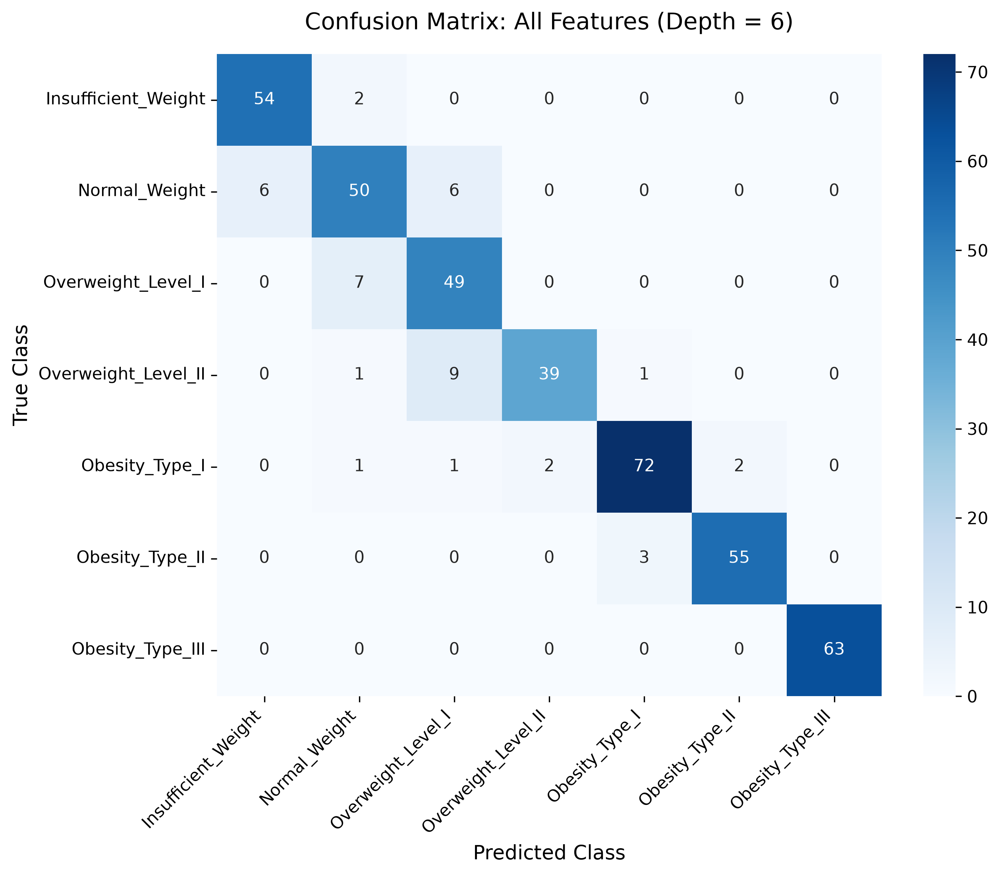


================ Lifestyle Only (Depth = 6) ================
Test Accuracy: 67.85%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.846     0.589     0.695        56
      Normal_Weight      0.545     0.677     0.604        62
 Overweight_Level_I      0.566     0.769     0.652        78
Overweight_Level_II      0.710     0.845     0.772        58
     Obesity_Type_I      0.984     1.000     0.992        63
    Obesity_Type_II      0.800     0.357     0.494        56
   Obesity_Type_III      0.465     0.400     0.430        50

           accuracy                          0.678       423
          macro avg      0.702     0.663     0.663       423
       weighted avg      0.701     0.678     0.671       423

Saved tree plot to: pictures/tree_lifestyle_only_depth_6.svg


Saved confusion matrix to: pictures/confusion_matrix_lifestyle_only_depth_6.png



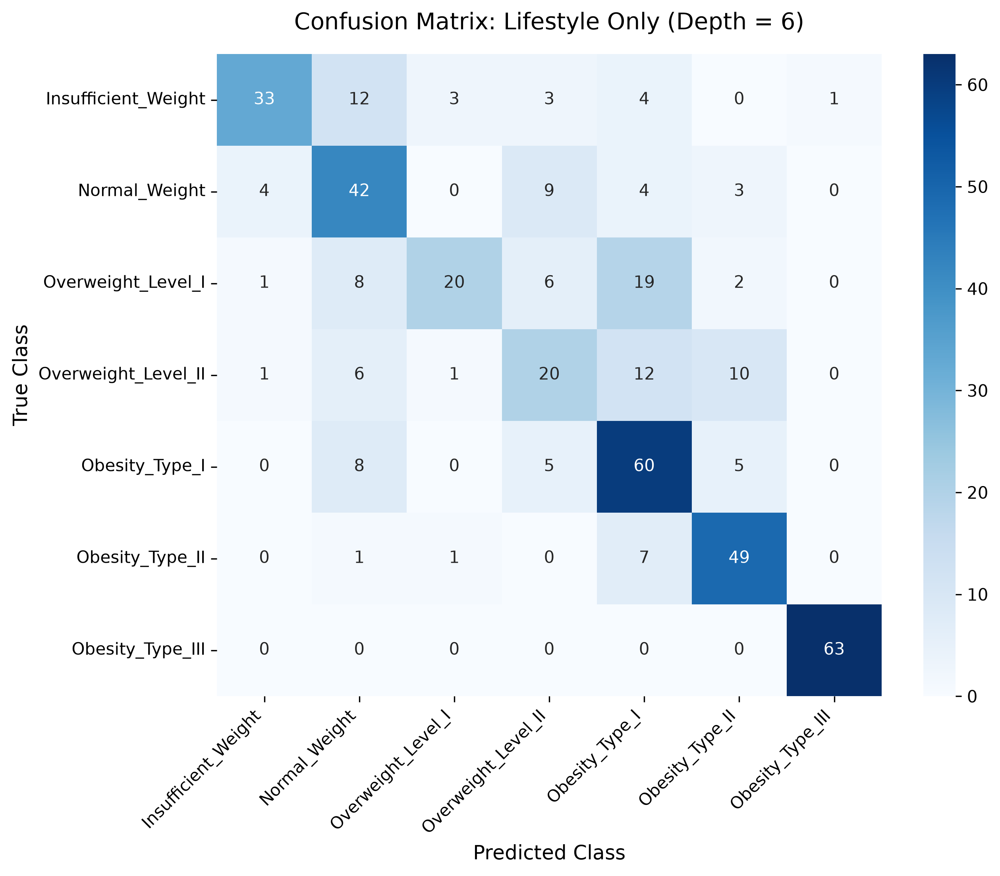

In [250]:









import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Create a dedicated folder for pictures/plots (leaving your data folder untouched)
output_dir = "pictures"
os.makedirs(output_dir, exist_ok=True)

# 2. Define Feature Sets
cols_to_drop_all = ["NObeyesdad", "Calculated_BMI", "SMOKE"]
X_all = df.drop(columns=cols_to_drop_all, errors="ignore")

cols_to_drop_lifestyle = ["NObeyesdad", "Calculated_BMI", "SMOKE", "Height", "Weight"]
X_lifestyle = df.drop(columns=cols_to_drop_lifestyle, errors="ignore")

y = df["NObeyesdad"]

# Split data for both feature sets (using the same random state for fair comparison)
X_all_train, X_all_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)
X_life_train, X_life_test, _, _ = train_test_split(
    X_lifestyle, y, test_size=0.2, random_state=42
)

# 3. Configure the 4 Tree Experiments (models_config)
models_config = [
    {
        "name": "All Features (Depth = 3)",
        "model": DecisionTreeClassifier(max_depth=3, random_state=42),
        "X_tr": X_all_train,
        "X_te": X_all_test,
        "features": X_all.columns,
        "tree_figsize": (35, 12),
        "fontsize": 14,
    },
    {
        "name": "Lifestyle Only (Depth = 3)",
        "model": DecisionTreeClassifier(max_depth=3, random_state=42),
        "X_tr": X_life_train,
        "X_te": X_life_test,
        "features": X_lifestyle.columns,
        "tree_figsize": (35, 12),
        "fontsize": 14,
    },
    {
        "name": "All Features (Depth = 6)",
        "model": DecisionTreeClassifier(max_depth=6, random_state=42),
        "X_tr": X_all_train,
        "X_te": X_all_test,
        "features": X_all.columns,
        "tree_figsize": (110, 32),  
        "fontsize": 9,                 
    },
    {
        "name": "Lifestyle Only (Depth = 6)",
        "model": DecisionTreeClassifier(max_depth=6, random_state=42),
        "X_tr": X_life_train,
        "X_te": X_life_test,
        "features": X_lifestyle.columns,
        "tree_figsize": (110, 32),  
        "fontsize": 7,               
    },
]

# Map your text labels to encoded integer values using your correct_order
class_indices = list(label_encoders["NObeyesdad"].transform(correct_order))

# 4. Train, Evaluate, and Plot Each Model in the Loop
for cfg in models_config:
    print(f"\n================ {cfg['name']} ================")
    
    # Fit model
    clf = cfg["model"]
    clf.fit(cfg["X_tr"], y_train)
    
    # Predictions
    y_pred = clf.predict(cfg["X_te"])
    
    # Print Metrics
    acc = accuracy_score(y_test, y_pred)
    print(f"Test Accuracy: {acc * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=correct_order, digits=3))
    
    # Create file-safe string tag
    file_tag = cfg["name"].lower().replace(" = ", "_").replace("(", "").replace(")", "").replace(" ", "_")
    
    # Plot and Save Tree Diagram (SVG format inside 'pictures/' folder)
    plt.figure(figsize=cfg["tree_figsize"], dpi=300)
    plot_tree(
        clf,
        feature_names=list(cfg["features"]),
        class_names=list(label_encoders["NObeyesdad"].classes_),
        filled=True,
        rounded=True,
        fontsize=cfg["fontsize"],
        precision=0
    )
    plt.title(f"Decision Tree Structure: {cfg['name']}", fontsize=18, pad=20)
    
    tree_filename = os.path.join(output_dir, f"tree_{file_tag}.svg")
    plt.savefig(tree_filename, format="svg", bbox_inches="tight")
    print(f"Saved tree plot to: {tree_filename}")
    plt.show()
    
    # Plot and Save Ordered Confusion Matrix Heatmap (PNG format inside 'pictures/' folder)
    cm = confusion_matrix(y_test, y_pred, labels=class_indices)
    plt.figure(figsize=(9, 7), dpi=300)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=correct_order,
        yticklabels=correct_order
    )
    plt.xlabel("Predicted Class", fontsize=12)
    plt.ylabel("True Class", fontsize=12)
    plt.title(f"Confusion Matrix: {cfg['name']}", fontsize=14, pad=15)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    
    cm_filename = os.path.join(output_dir, f"confusion_matrix_{file_tag}.png")
    plt.savefig(cm_filename, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {cm_filename}\n")
    plt.show()
